# Rearrangement - Transport - Test

In [3]:
from pytweezer.experiment.motmaster_client import MotMasterClient
from pytweezer.drivers.imagemX2 import ImagEMX2Camera
from pytweezer.drivers.slm import SLM
from pytweezer.drivers.thorcam import ThorCamera
from pytweezer.experiment.experiment_parameter_manager import ExpParameterManager
import pytweezer.phasemask as pm
import pytweezer.analysis as an
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

ExpParams = ExpParameterManager()

In [4]:
exp : MotMasterClient = MotMasterClient()
slm : SLM = SLM()
hamcam : ImagEMX2Camera = ImagEMX2Camera()

Rb MotMasterClient initialised.
SLM 1 initialised: 1024x1024 @ 8-bit, serial 7752, 40.230 degC
SLM 1 loaded LUT "C:\Program Files\Meadowlark Optics\Blink Plus\LUT Files\slm40_at852.LUT"
ImagEM X2 camera initialised.


In [5]:
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)
exp.set_motmaster_experiment("RbTweezerBasic2026_2")

hamcam.set_trigger_source("ext")
hamcam.set_external_exposure_mode()
hamcam.enable_em_gain(True)
hamcam.enable_direct_em_gain(True)
hamcam.set_sensitivity(600)
hamcam.timeout = 60*5
X0, Y0, WIDTH, HEIGHT = 110, 220, 256, 256
hamcam.set_roi(X0, WIDTH, Y0, HEIGHT)

In [6]:
hamcam.timeout = 60*5

## Phasemask Generator

In [7]:
dx, dy = 8.0, 12.0
PM = pm.OptimisationBasedPhasemaskGeneratorGPU3D(
                 wavelength_um=0.852,
                 focal_length_mm=17.3,
                 slm_pitch_um=17,
                 slm_res=(1024,1024),
                 input_beam_waist_mm=16,
                 fresnel_f_mm=1072,
                 blaze_dx_dy_um=(40+dx, -8+dy),
                 zernike_coeff_dict={5:1.195, 6:0.725, 7:0.970, 8:0.478, 9:-1.091, 10:0.303, 11:0.021, 12:0.072, 13:0.049})

gauss2d = lambda x, y, A, x0, y0, sx, sy, offset: (A * np.exp(-(((x - x0) ** 2) / (2 * sx ** 2) + ((y - y0) ** 2) / (2 * sy ** 2)))) + offset
A, x0, y0, sx, sy, offset = [-2.14197604e+03, -1.11443850e+01 - dx, 2.09919600e+00 - dy, 2.95002910e+03, 2.64281503e+03, 2.14239505e+03]

--- System Configuration ---
SLM Plane Width: 17.41 mm
SLM Plane Height: 17.41 mm
Focal Plane Resolution x (pixel size): 0.8467 um
Focal Plane Resolution y (pixel size): 0.8467 um
Focal Plane Width: 867.04 um
Focal Plane Height: 867.04 um
Fresnel Lens Focal Length: 1072.00 mm
Blazed Grating Displacement (dx, dy): (48.0, 4.0) um


Phasemask 1

In [8]:
W1 = np.ones((13,13))
spacing_um = 5.0

w_n, theta_n, x_n1, y_n1, z_n1 = PM.generate_weighted_array(W1, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n1, y_n1, A, x0, y0, sx, sy, offset)

terms1 = [w_n, theta_n, x_n1, y_n1, z_n1]
pm_array1, terms1, _ = PM.superposition_optimization(terms1, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 13x13
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 6.40e-06 | Uniformity: 42.70% | Min/Max ratio: 0.042
Iteration 010 | Mean-Squared Error: 3.57e-08 | Uniformity: 78.88% | Min/Max ratio: 0.411
Iteration 020 | Mean-Squared Error: 1.08e-08 | Uniformity: 78.86% | Min/Max ratio: 0.411
Iteration 030 | Mean-Squared Error: 4.69e-09 | Uniformity: 78.96% | Min/Max ratio: 0.438
Iteration 040 | Mean-Squared Error: 2.76e-09 | Uniformity: 78.87% | Min/Max ratio: 0.439
Iteration 050 | Mean-Squared Error: 1.57e-09 | Uniformity: 78.95% | Min/Max ratio: 0.433
Iteration 060 | Mean-Squared Error: 1.57e-09 | Uniformity: 79.01% | Min/Max ratio: 0.433
Iteration 070 | Mean-Squared Error: 8.40e-10 | Uniformity: 78.97% | Min/Max ratio: 0.437
Iteration 080 | Mean-Squared Error: 5.80e-10 | Uniformity: 78.94% | Min/Max ratio: 0.434
Iteration 090 | Mean-Squared Error: 1.29e-09 | Uniformity: 78.95% | Min/Max ratio: 0.431


Phasemask 2

In [9]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.44e-05 | Uniformity: 53.96% | Min/Max ratio: 0.095
Iteration 010 | Mean-Squared Error: 1.17e-07 | Uniformity: 85.18% | Min/Max ratio: 0.551
Iteration 020 | Mean-Squared Error: 3.93e-08 | Uniformity: 84.89% | Min/Max ratio: 0.537
Iteration 030 | Mean-Squared Error: 4.49e-08 | Uniformity: 85.29% | Min/Max ratio: 0.564
Iteration 040 | Mean-Squared Error: 8.20e-09 | Uniformity: 85.17% | Min/Max ratio: 0.561
Iteration 050 | Mean-Squared Error: 3.54e-09 | Uniformity: 85.18% | Min/Max ratio: 0.562
Iteration 060 | Mean-Squared Error: 4.10e-09 | Uniformity: 85.17% | Min/Max ratio: 0.564
Iteration 070 | Mean-Squared Error: 5.79e-09 | Uniformity: 85.19% | Min/Max ratio: 0.565
Iteration 080 | Mean-Squared Error: 1.66e-09 | Uniformity: 85.18% | Min/Max ratio: 0.563
Iteration 090 | Mean-Squared Error: 6.12e-10 | Uniformity: 85.18% | Min/Max ratio: 0.563
It

Phasemask 3

In [10]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 5.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.00e-05 | Uniformity: 56.14% | Min/Max ratio: 0.104
Iteration 010 | Mean-Squared Error: 1.57e-07 | Uniformity: 84.49% | Min/Max ratio: 0.538
Iteration 020 | Mean-Squared Error: 5.33e-08 | Uniformity: 85.21% | Min/Max ratio: 0.555
Iteration 030 | Mean-Squared Error: 1.45e-08 | Uniformity: 85.03% | Min/Max ratio: 0.550
Iteration 040 | Mean-Squared Error: 4.08e-09 | Uniformity: 85.13% | Min/Max ratio: 0.558
Iteration 050 | Mean-Squared Error: 4.08e-09 | Uniformity: 85.14% | Min/Max ratio: 0.560
Iteration 060 | Mean-Squared Error: 3.96e-09 | Uniformity: 85.15% | Min/Max ratio: 0.560
Iteration 070 | Mean-Squared Error: 2.10e-09 | Uniformity: 85.17% | Min/Max ratio: 0.561
Iteration 080 | Mean-Squared Error: 1.46e-09 | Uniformity: 85.17% | Min/Max ratio: 0.563
Iteration 090 | Mean-Squared Error: 1.90e-09 | Uniformity: 85.18% | Min/Max ratio: 0.563
It

Upload initial phasemask

In [25]:
pm_composite = PM.superimpose([pm_array1, PM.fresnel, PM.blaze, PM.zernike])
pm_composite_uint8 = PM.transform_phase_8bit(pm_composite).get()
slm.update_mask(pm_composite_uint8)

## Baseline

Parameter 'conversion_factor' set to 0.009508957628343926.
Parameter 'conversion_offset' set to 1916.911865234375.
Parameters saved.


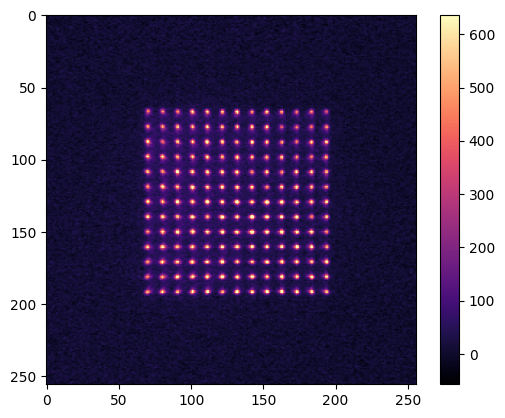

In [12]:
# Experiment and camera setup
n_iterations = 100
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(n_iterations)
hamcam.setup_acquisition("snap", n_iterations * 2)
hamcam.start_acquisition()
exp.start_motmaster_experiment({
    "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
    "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
    "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"),
    "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
    "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"),
    "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
    "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"),
    "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
    "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
    "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
    "tTweezerSetVVA0": 0.0, "tTweezerSetVVA1": 0.0,
    "BackgroundDrop": 1})

imgs = hamcam.acquire_n_frames(n_iterations * 2)
imgs1, imgs2 = imgs[::2], imgs[1::2]
img_average = an.tweezer_show_bg_subtracted(imgs1, imgs2, cmap='magma', show=True, vmaxfactor=0.6, show_grid=True)

ExpParams.set_parameter("conversion_factor", hamcam.dcam.get_attribute_value("CONVERSION FACTOR COEFF"))
ExpParams.set_parameter("conversion_offset", hamcam.dcam.get_attribute_value("CONVERSION FACTOR OFFSET"))
ExpParams.save_parameters()

Looking for trap sites...
169 Atoms Detected.
Parameter 'x_centre' set to 131.28402366863907.
Parameter 'y_centre' set to 128.97041420118344.
Parameters saved.


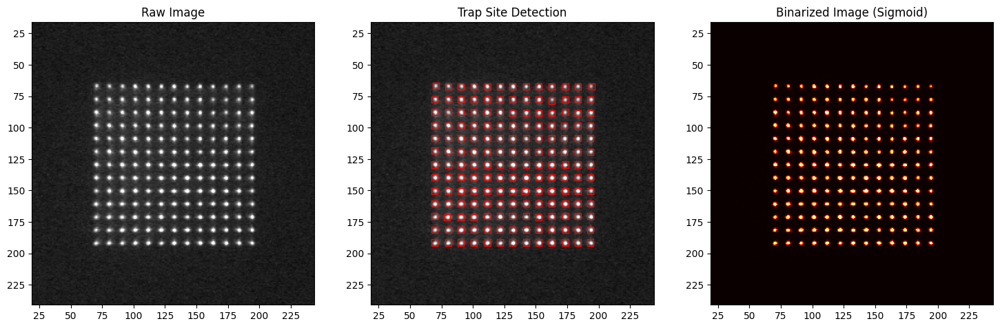

Trap (0) Loading Probability : 56.00 %
Trap (1) Loading Probability : 59.00 %
Trap (2) Loading Probability : 56.00 %
Trap (3) Loading Probability : 51.00 %
Trap (4) Loading Probability : 62.00 %
Trap (5) Loading Probability : 52.00 %
Trap (6) Loading Probability : 62.00 %
Trap (7) Loading Probability : 54.00 %
Trap (8) Loading Probability : 62.00 %
Trap (9) Loading Probability : 58.00 %
Trap (10) Loading Probability : 52.00 %
Trap (11) Loading Probability : 58.00 %
Trap (12) Loading Probability : 63.00 %
Trap (13) Loading Probability : 58.00 %
Trap (14) Loading Probability : 52.00 %
Trap (15) Loading Probability : 46.00 %
Trap (16) Loading Probability : 39.00 %
Trap (17) Loading Probability : 54.00 %
Trap (18) Loading Probability : 57.00 %
Trap (19) Loading Probability : 55.00 %
Trap (20) Loading Probability : 53.00 %
Trap (21) Loading Probability : 57.00 %
Trap (22) Loading Probability : 54.00 %
Trap (23) Loading Probability : 59.00 %
Trap (24) Loading Probability : 54.00 %
Trap (25) 

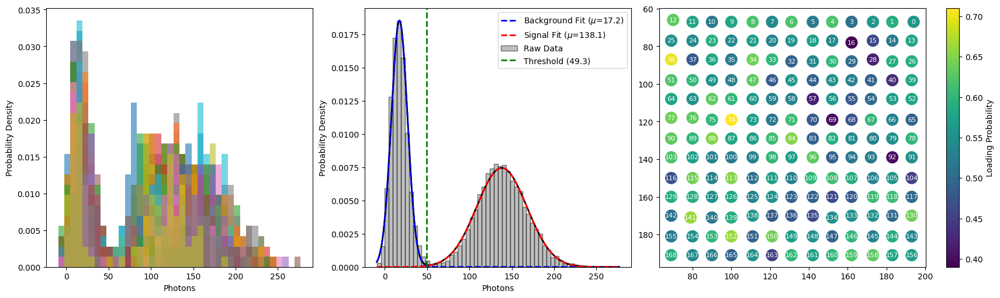

In [13]:
feature_size, window = 10, 5
grid_positions, detection_threshold = an.detect_trap_sites(img_average, 13*13, detection_step=100)
an.set_array_centre(grid_positions)
grid_positions = an.index_grid_positions(grid_positions, x_n1, y_n1)
an.visualize_results(img_average, grid_positions, margin=50, window_size=window, threshold=detection_threshold, vmaxfactor=0.5, bin_sharpness=20, bin_thresh_factor=0.9)
imgs_n_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs1]
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(imgs_n_filtered, grid_positions, threshold=100, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=True, verbose=True, show_site_labels=True)

Trap (0) Loading Probability : 56.00 %
Trap (1) Loading Probability : 60.00 %
Trap (2) Loading Probability : 56.00 %
Trap (3) Loading Probability : 51.00 %
Trap (4) Loading Probability : 62.00 %
Trap (5) Loading Probability : 52.00 %
Trap (6) Loading Probability : 63.00 %
Trap (7) Loading Probability : 54.00 %
Trap (8) Loading Probability : 62.00 %
Trap (9) Loading Probability : 59.00 %
Trap (10) Loading Probability : 52.00 %
Trap (11) Loading Probability : 58.00 %
Trap (12) Loading Probability : 63.00 %
Trap (13) Loading Probability : 59.00 %
Trap (14) Loading Probability : 52.00 %
Trap (15) Loading Probability : 46.00 %
Trap (16) Loading Probability : 39.00 %
Trap (17) Loading Probability : 54.00 %
Trap (18) Loading Probability : 57.00 %
Trap (19) Loading Probability : 55.00 %
Trap (20) Loading Probability : 54.00 %
Trap (21) Loading Probability : 57.00 %
Trap (22) Loading Probability : 54.00 %
Trap (23) Loading Probability : 56.00 %
Trap (24) Loading Probability : 53.00 %
Trap (25) 

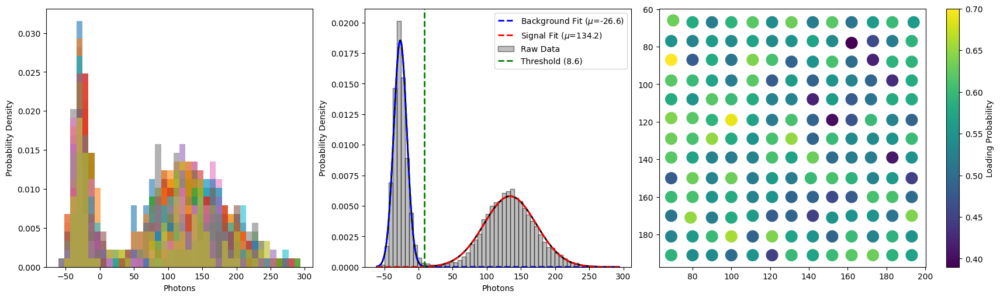

In [14]:
# Analyse images (fliplr) with indexed grid positions - PSF
psf_window = 9

# Templates come from the raw frames - the matched filter needs no top-hat.
scorer = an.SiteScorer.from_images(imgs1, grid_positions, window_size=psf_window)
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(
    imgs1, grid_positions, scorer=scorer, threshold_detection=True, binning=60)

scorer.threshold = threshold_1 * 1.0
print(f"PSF threshold {scorer.threshold:.2f} photons, detection fidelity {fidelity*100:.3f} %")

---
## Rearrangement + Transport Test

In [32]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])


await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear"
)

Occupancy via PSF detector (window 9, threshold 8.3).
Transport node initialised.


In [33]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [34]:
N_iterations = 1  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 1
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.8930 ms total
Transport complete: 12 frames, 11.1093 ms total
Images acquired from rearrangement node.


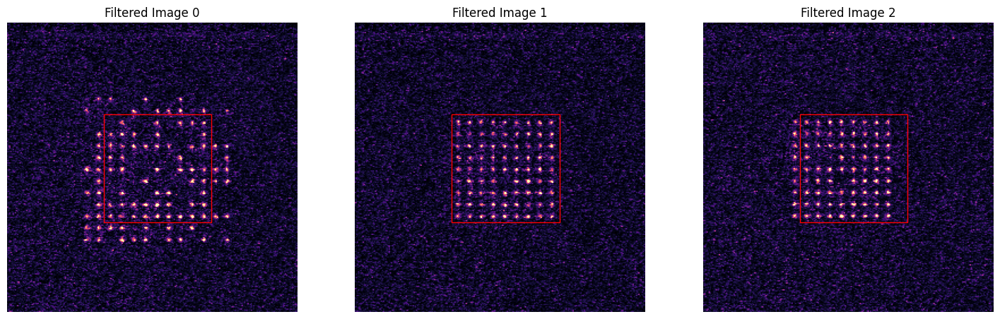

In [35]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

---
## Rearrangement + Transport Test

Phasemask 3

In [37]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

z_n3 += 5.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.44e-05 | Uniformity: 65.67% | Min/Max ratio: 0.167
Iteration 010 | Mean-Squared Error: 1.39e-07 | Uniformity: 84.09% | Min/Max ratio: 0.543
Iteration 020 | Mean-Squared Error: 1.49e-08 | Uniformity: 85.22% | Min/Max ratio: 0.557
Iteration 030 | Mean-Squared Error: 1.09e-08 | Uniformity: 85.40% | Min/Max ratio: 0.562
Iteration 040 | Mean-Squared Error: 2.36e-08 | Uniformity: 85.42% | Min/Max ratio: 0.555
Iteration 050 | Mean-Squared Error: 2.27e-08 | Uniformity: 85.23% | Min/Max ratio: 0.566
Iteration 060 | Mean-Squared Error: 1.58e-08 | Uniformity: 84.92% | Min/Max ratio: 0.557
Iteration 070 | Mean-Squared Error: 5.42e-09 | Uniformity: 85.04% | Min/Max ratio: 0.561
Iteration 080 | Mean-Squared Error: 3.40e-09 | Uniformity: 85.09% | Min/Max ratio: 0.561
Iteration 090 | Mean-Squared Error: 1.47e-09 | Uniformity: 85.13% | Min/Max ratio: 0.563
It

In [38]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])


await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear"
)

Occupancy via PSF detector (window 9, threshold 9.7).
Transport node initialised.


In [39]:
N_iterations = 1  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 1
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 25.3110 ms total
Transport complete: 6 frames, 6.1831 ms total
Images acquired from rearrangement node.


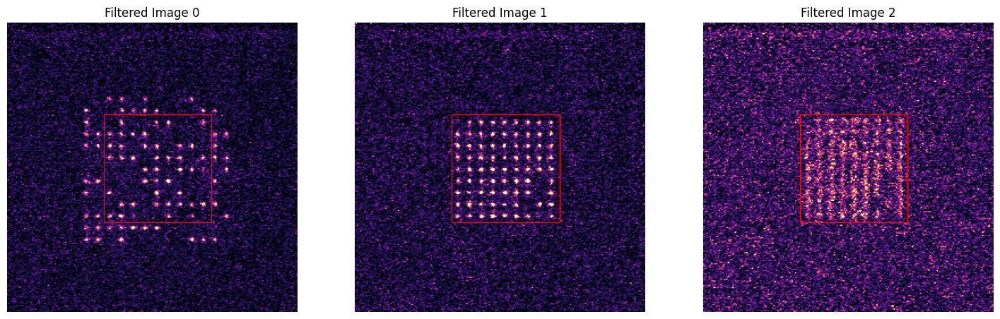

In [40]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

---
## Rearrangement + Transport Test

Phasemask 3

In [36]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

for i in range(len(z_n3)):
    if i % 2 == 0:
        z_n3[i] += 5.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.90e-05 | Uniformity: 55.04% | Min/Max ratio: 0.131
Iteration 010 | Mean-Squared Error: 8.59e-08 | Uniformity: 84.89% | Min/Max ratio: 0.547
Iteration 020 | Mean-Squared Error: 1.92e-08 | Uniformity: 85.19% | Min/Max ratio: 0.553
Iteration 030 | Mean-Squared Error: 6.24e-09 | Uniformity: 85.25% | Min/Max ratio: 0.563
Iteration 040 | Mean-Squared Error: 2.65e-09 | Uniformity: 85.21% | Min/Max ratio: 0.566
Iteration 050 | Mean-Squared Error: 2.58e-09 | Uniformity: 85.15% | Min/Max ratio: 0.563
Iteration 060 | Mean-Squared Error: 6.20e-09 | Uniformity: 85.14% | Min/Max ratio: 0.561
Iteration 070 | Mean-Squared Error: 1.21e-08 | Uniformity: 85.11% | Min/Max ratio: 0.557
Iteration 080 | Mean-Squared Error: 1.09e-08 | Uniformity: 85.11% | Min/Max ratio: 0.558
Iteration 090 | Mean-Squared Error: 2.42e-09 | Uniformity: 85.13% | Min/Max ratio: 0.561
It

In [37]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])


await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear"
)

Occupancy via PSF detector (window 9, threshold 8.3).
Transport node initialised.


In [38]:
N_iterations = 1  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 1
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 21.0509 ms total
Transport complete: 6 frames, 6.5176 ms total
Images acquired from rearrangement node.


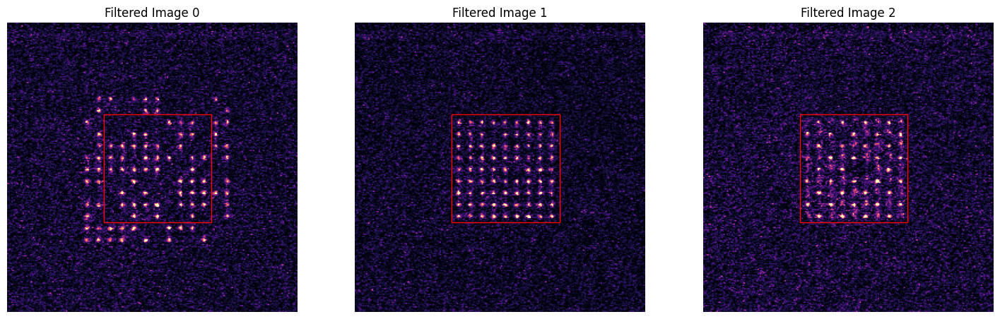

In [39]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

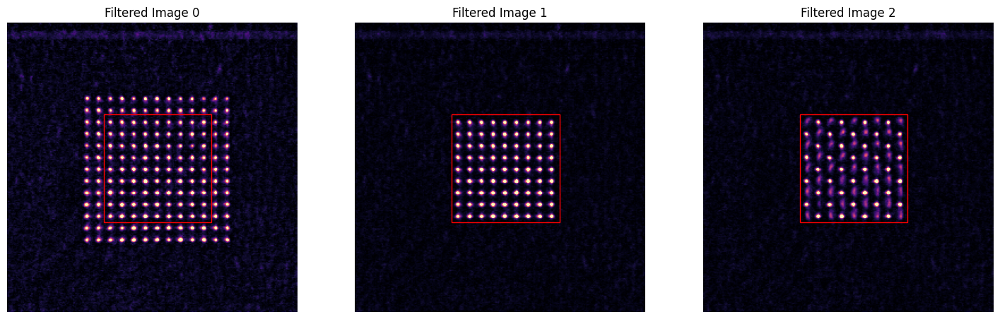

In [48]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

---
## Rearrangement + Transport Test

Phasemask 3

In [51]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

dz = np.zeros_like(z_n3)
for i in range(len(z_n3)):
    if i % 2 == 0:
        dz[i] = 5.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.92e-05 | Uniformity: 49.44% | Min/Max ratio: 0.043
Iteration 010 | Mean-Squared Error: 1.23e-07 | Uniformity: 85.13% | Min/Max ratio: 0.547
Iteration 020 | Mean-Squared Error: 3.89e-08 | Uniformity: 84.77% | Min/Max ratio: 0.544
Iteration 030 | Mean-Squared Error: 3.38e-08 | Uniformity: 85.20% | Min/Max ratio: 0.563
Iteration 040 | Mean-Squared Error: 1.55e-08 | Uniformity: 85.25% | Min/Max ratio: 0.568
Iteration 050 | Mean-Squared Error: 7.39e-09 | Uniformity: 85.22% | Min/Max ratio: 0.566
Iteration 060 | Mean-Squared Error: 4.54e-09 | Uniformity: 85.15% | Min/Max ratio: 0.558
Iteration 070 | Mean-Squared Error: 3.47e-09 | Uniformity: 85.13% | Min/Max ratio: 0.560
Iteration 080 | Mean-Squared Error: 8.91e-10 | Uniformity: 85.15% | Min/Max ratio: 0.561
Iteration 090 | Mean-Squared Error: 3.49e-10 | Uniformity: 85.16% | Min/Max ratio: 0.562
It

In [52]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    d_lift=dz
)

Occupancy via PSF detector (window 9, threshold 8.3).
Transport node initialised.


In [53]:
N_iterations = 1  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 1
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 21.4789 ms total
Transport complete: 20 frames, 19.4796 ms total
Images acquired from rearrangement node.


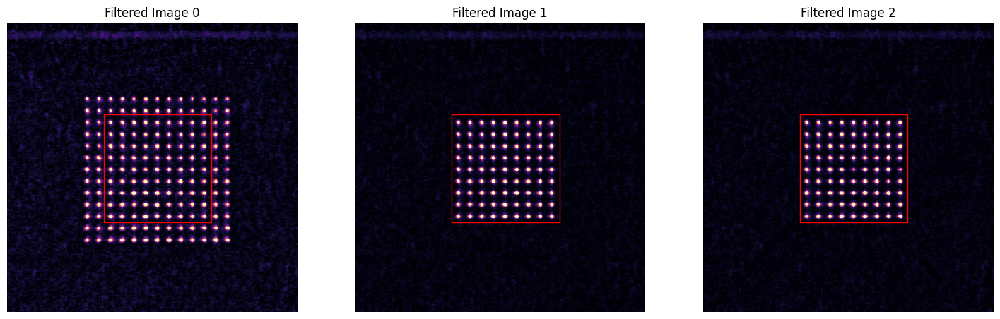

In [61]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

---
## Rearrangement + Transport Test

Phasemask 3

In [63]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

dz = np.zeros_like(z_n3)
for i in range(len(z_n3)):
    if i % 2 == 0:
        dz[i] = 10.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.84e-05 | Uniformity: 48.26% | Min/Max ratio: 0.108
Iteration 010 | Mean-Squared Error: 1.45e-07 | Uniformity: 84.79% | Min/Max ratio: 0.522
Iteration 020 | Mean-Squared Error: 5.99e-08 | Uniformity: 84.85% | Min/Max ratio: 0.553
Iteration 030 | Mean-Squared Error: 7.60e-09 | Uniformity: 85.21% | Min/Max ratio: 0.560
Iteration 040 | Mean-Squared Error: 5.65e-09 | Uniformity: 85.16% | Min/Max ratio: 0.563
Iteration 050 | Mean-Squared Error: 2.64e-09 | Uniformity: 85.14% | Min/Max ratio: 0.564
Iteration 060 | Mean-Squared Error: 8.19e-10 | Uniformity: 85.17% | Min/Max ratio: 0.565
Iteration 070 | Mean-Squared Error: 2.81e-10 | Uniformity: 85.19% | Min/Max ratio: 0.565
Iteration 080 | Mean-Squared Error: 9.71e-11 | Uniformity: 85.19% | Min/Max ratio: 0.564
Iteration 090 | Mean-Squared Error: 3.43e-11 | Uniformity: 85.19% | Min/Max ratio: 0.564
It

In [68]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    d_lift=dz
)

Occupancy via PSF detector (window 9, threshold 8.3).
Transport node initialised.


In [69]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Reset-image acquisition failed. Exception: 
Rearrangement complete: 24 frames, 21.2802 ms total
Transport complete: 39 frames, 34.1504 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Reset-image acquisition failed. Exception: 
Rearrangement complete: 30 frames, 24.9678 ms total
Transport complete: 39 frames, 33.8779 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Reset-image acquisition failed. Exception:

CancelledError: 

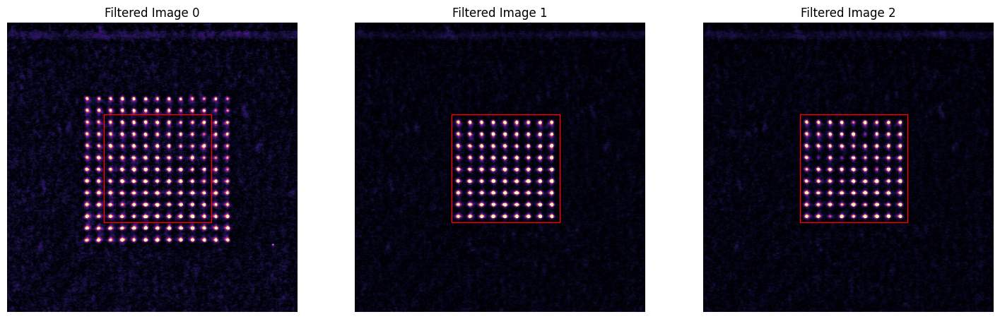

In [66]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Trap (0) Loading Probability : 98.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 95.00 %
Trap (3) Loading Probability : 39.00 %
Trap (4) Loading Probability : 95.00 %
Trap (5) Loading Probability : 89.00 %
Trap (6) Loading Probability : 90.00 %
Trap (7) Loading Probability : 85.00 %
Trap (8) Loading Probability : 97.00 %
Trap (9) Loading Probability : 72.00 %
Trap (10) Loading Probability : 76.00 %
Trap (11) Loading Probability : 96.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 93.00 %
Trap (14) Loading Probability : 25.00 %
Trap (15) Loading Probability : 92.00 %
Trap (16) Loading Probability : 80.00 %
Trap (17) Loading Probability : 94.00 %
Trap (18) Loading Probability : 94.00 %
Trap (19) Loading Probability : 92.00 %
Trap (20) Loading Probability : 78.00 %
Trap (21) Loading Probability : 88.00 %
Trap (22) Loading Probability : 64.00 %
Trap (23) Loading Probability : 87.00 %
Trap (24) Loading Probability : 88.00 %
Trap (25) 

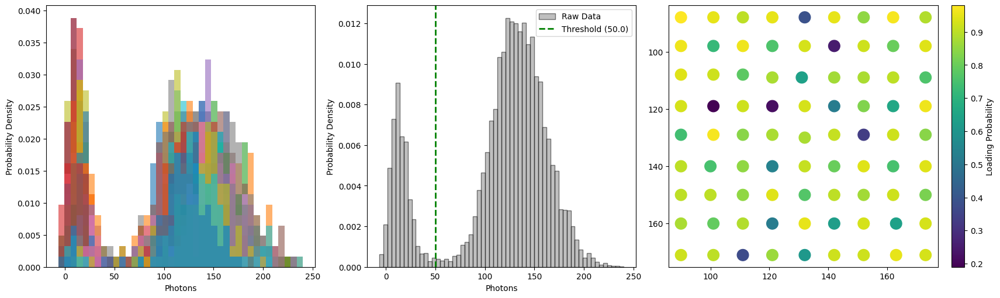

In [67]:
n = 2
imgs_n_2 = tot_imgs[:, n, :, :]
imgs_n_mean_2 = imgs_n_2.mean(axis=0)
imgs_n_mean_filtered_2 = an.morphological_tophat_high_pass(imgs_n_mean_2, feature_size=feature_size)

imgs_n_filtered_2 = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_n_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_n_filtered_2, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

---
## Rearrangement + Transport Test

In [24]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

Phasemask 2

In [59]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = W2.flatten() * gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.54e-05 | Uniformity: 55.06% | Min/Max ratio: 0.100
Iteration 010 | Mean-Squared Error: 3.75e-07 | Uniformity: 84.26% | Min/Max ratio: 0.498
Iteration 020 | Mean-Squared Error: 9.28e-08 | Uniformity: 85.02% | Min/Max ratio: 0.577
Iteration 030 | Mean-Squared Error: 2.22e-08 | Uniformity: 85.01% | Min/Max ratio: 0.551
Iteration 040 | Mean-Squared Error: 1.06e-08 | Uniformity: 85.13% | Min/Max ratio: 0.556
Iteration 050 | Mean-Squared Error: 3.14e-09 | Uniformity: 85.10% | Min/Max ratio: 0.562
Iteration 060 | Mean-Squared Error: 2.17e-09 | Uniformity: 85.14% | Min/Max ratio: 0.564
Iteration 070 | Mean-Squared Error: 4.18e-09 | Uniformity: 85.16% | Min/Max ratio: 0.566
Iteration 080 | Mean-Squared Error: 6.16e-09 | Uniformity: 85.01% | Min/Max ratio: 0.560
Iteration 090 | Mean-Squared Error: 5.15e-09 | Uniformity: 85.10% | Min/Max ratio: 0.562
It

Phasemask 3

In [60]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = W3.flatten() * gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)
x_n3 += 5.0

dz = 5.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.22e-05 | Uniformity: 56.69% | Min/Max ratio: 0.052
Iteration 010 | Mean-Squared Error: 2.06e-07 | Uniformity: 84.76% | Min/Max ratio: 0.542
Iteration 020 | Mean-Squared Error: 4.53e-08 | Uniformity: 84.69% | Min/Max ratio: 0.553
Iteration 030 | Mean-Squared Error: 6.38e-08 | Uniformity: 84.58% | Min/Max ratio: 0.528
Iteration 040 | Mean-Squared Error: 2.48e-08 | Uniformity: 85.52% | Min/Max ratio: 0.565
Iteration 050 | Mean-Squared Error: 1.05e-08 | Uniformity: 85.31% | Min/Max ratio: 0.567
Iteration 060 | Mean-Squared Error: 6.14e-09 | Uniformity: 85.31% | Min/Max ratio: 0.564
Iteration 070 | Mean-Squared Error: 6.73e-09 | Uniformity: 85.17% | Min/Max ratio: 0.562
Iteration 080 | Mean-Squared Error: 2.02e-09 | Uniformity: 85.11% | Min/Max ratio: 0.563
Iteration 090 | Mean-Squared Error: 1.12e-09 | Uniformity: 85.12% | Min/Max ratio: 0.564
It

In [61]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.5,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    d_lift=dz
)

Occupancy via PSF detector (window 9, threshold 8.6).
Transport node initialised.


In [63]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.9716 ms total
Transport complete: 33 frames, 29.7364 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 24.9042 ms total
Transport complete: 33 frames, 28.9514 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 38 frames, 30.5188 ms total
Transport complete: 33 frames, 28.9075 ms total
Images acquired from rearrange

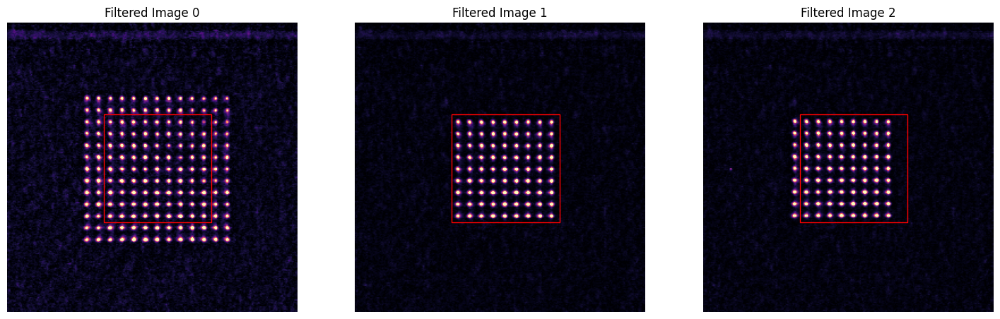

In [64]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Trap (0) Loading Probability : 98.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 95.00 %
Trap (3) Loading Probability : 39.00 %
Trap (4) Loading Probability : 95.00 %
Trap (5) Loading Probability : 89.00 %
Trap (6) Loading Probability : 90.00 %
Trap (7) Loading Probability : 85.00 %
Trap (8) Loading Probability : 97.00 %
Trap (9) Loading Probability : 72.00 %
Trap (10) Loading Probability : 76.00 %
Trap (11) Loading Probability : 96.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 93.00 %
Trap (14) Loading Probability : 25.00 %
Trap (15) Loading Probability : 92.00 %
Trap (16) Loading Probability : 80.00 %
Trap (17) Loading Probability : 94.00 %
Trap (18) Loading Probability : 94.00 %
Trap (19) Loading Probability : 92.00 %
Trap (20) Loading Probability : 78.00 %
Trap (21) Loading Probability : 88.00 %
Trap (22) Loading Probability : 64.00 %
Trap (23) Loading Probability : 87.00 %
Trap (24) Loading Probability : 88.00 %
Trap (25) 

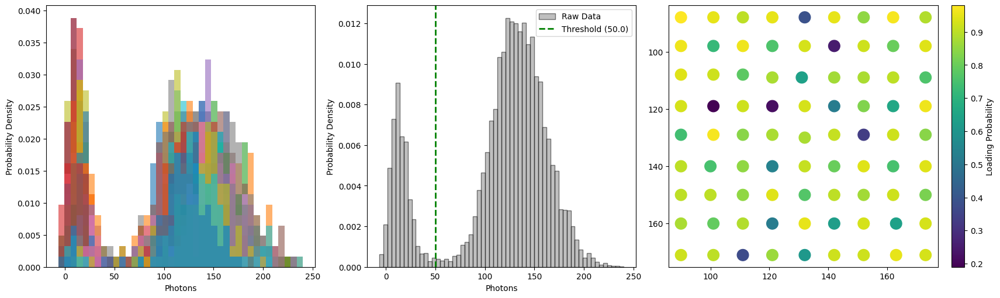

In [ ]:
n = 2
imgs_n_2 = tot_imgs[:, n, :, :]
imgs_n_mean_2 = imgs_n_2.mean(axis=0)
imgs_n_mean_filtered_2 = an.morphological_tophat_high_pass(imgs_n_mean_2, feature_size=feature_size)

imgs_n_filtered_2 = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_n_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_n_filtered_2, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

---
## Rearrangement + Transport Test

In [106]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

Phasemask 2

In [107]:
W2a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n2_a, y_n2_a, z_n2_a = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W2a.flatten() * gauss2d(x_n2_a, y_n2_a, A, x0, y0, sx, sy, offset)
y_n2_a *= 0.5

w_n_b, theta_n_b, x_n2_b, y_n2_b, z_n2_b = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W2a.flatten() * gauss2d(x_n2_b, y_n2_b, A, x0, y0, sx, sy, offset)
y_n2_b *= 0.5
x_n2_b += 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n2 = np.concatenate((x_n2_a, x_n2_b))
y_n2 = np.concatenate((y_n2_a, y_n2_b))
z_n2 = np.concatenate((z_n2_a, z_n2_b))

x_n2, y_n2 = pm.rotate_positions(x_n2, y_n2, angle_degrees=2.5)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.66e-05 | Uniformity: 41.19% | Min/Max ratio: 0.070
Iteration 010 | Mean-Squared Error: 5.60e-08 | Uniformity: 75.04% | Min/Max ratio: 0.380
Iteration 020 | Mean-Squared Error: 1.76e-08 | Uniformity: 75.10% | Min/Max ratio: 0.393
Iteration 030 | Mean-Squared Error: 6.55e-09 | Uniformity: 75.18% | Min/Max ratio: 0.397
Iteration 040 | Mean-Squared Error: 6.27e-09 | Uniformity: 75.23% | Min/Max ratio: 0.396
Iteration 050 | Mean-Squared Error: 9.36e-10 | Uniformity: 75.21% | Min/Max ratio: 0.398
Iteration 060 | Mean-Squared Error: 2.73e-10 | Uniformity: 75.20% | Min/Max ratio: 0.399
Iteration 070 | Mean-Squared Error: 9.25e-11 | Uniformity: 75.19% | Min/Max ratio: 0.399
Iteration 080 | Mean-Squared Error: 4.22e-11 | Uniformity: 75.19% | Min/Max ratio: 0.399
Iteration 090 | Mean-Squared Error: 2

array([[ -0.48688197-14.56027076j,   3.33345029-14.32308199j,
         13.92520535-11.41252821j, ...,  13.10379333 -3.74728123j,
          8.79349238 -5.64562352j,   2.57311859-11.50102984j],
       [  3.99372767-11.39798713j,   5.54988569-10.89133191j,
          7.42540191-11.87320602j, ...,  -1.40120849 -5.08050296j,
         -3.43787539 -8.17908937j,  -0.19852248-10.94517858j],
       [ 12.08520873 +2.59973325j,  17.95048745+11.59950647j,
          7.60834484+10.71356463j, ..., -26.56655024-12.98683149j,
        -17.62946419-17.98344082j,  -2.51134632 -8.31265637j],
       ...,
       [ 23.23904637+16.47633624j,   7.9441835 +17.87945656j,
        -13.14338094 +3.82822537j, ...,  10.50264052+24.64129002j,
         28.01854619 +7.10226275j,  30.45190588 +6.07423719j],
       [  7.82761136 +6.53173286j,   2.94862915+15.29495536j,
         -4.85418311+14.74395371j, ...,  14.38477026 +9.89143285j,
         26.63351924 -1.49188949j,  18.9110172  -2.32067243j],
       [ -1.46160385 -6.6743

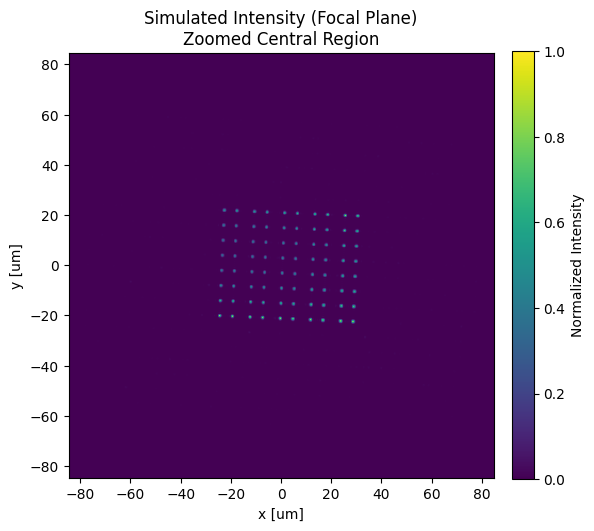

In [108]:
PM.simulate_focal_plane(pm_array2, show=True, zoom_pixels=100, cmap='viridis')

Phasemask 3

In [109]:
W3a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n3_a, y_n3_a, z_n3_a = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W3a.flatten() * gauss2d(x_n3_a, y_n3_a, A, x0, y0, sx, sy, offset)
y_n3_a *= 0.5

w_n_b, theta_n_b, x_n3_b, y_n3_b, z_n3_b = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W3a.flatten() * gauss2d(x_n3_b, y_n3_b, A, x0, y0, sx, sy, offset)
y_n3_b *= 0.5
x_n3_b -= 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n3 = np.concatenate((x_n3_a, x_n3_b))
y_n3 = np.concatenate((y_n3_a, y_n3_b))
z_n3 = np.concatenate((z_n3_a, z_n3_b))

x_n3, y_n3 = pm.rotate_positions(x_n3, y_n3, angle_degrees=2.5)

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.74e-05 | Uniformity: 40.88% | Min/Max ratio: 0.044
Iteration 010 | Mean-Squared Error: 5.65e-08 | Uniformity: 75.47% | Min/Max ratio: 0.387
Iteration 020 | Mean-Squared Error: 5.85e-08 | Uniformity: 75.04% | Min/Max ratio: 0.393
Iteration 030 | Mean-Squared Error: 1.12e-08 | Uniformity: 75.18% | Min/Max ratio: 0.394
Iteration 040 | Mean-Squared Error: 5.81e-09 | Uniformity: 75.19% | Min/Max ratio: 0.399
Iteration 050 | Mean-Squared Error: 1.83e-09 | Uniformity: 75.23% | Min/Max ratio: 0.397
Iteration 060 | Mean-Squared Error: 1.07e-09 | Uniformity: 75.20% | Min/Max ratio: 0.396
Iteration 070 | Mean-Squared Error: 1.14e-09 | Uniformity: 75.17% | Min/Max ratio: 0.397
Iteration 080 | Mean-Squared Error: 1.61e-09 | Uniformity: 75.18% | Min/Max ratio: 0.397
Iteration 090 | Mean-Squared Error: 2

array([[ 11.8536602  -0.25315712j,   7.29562867 -3.75192004j,
         -4.23868166 -6.06462886j, ...,   3.42050849+14.71476585j,
         -0.50306313+15.5755498j ,   5.17622506 +7.74995789j],
       [  1.2650582  -7.12679794j,   0.78274729-12.1827497j ,
         -2.05859804 -9.50503894j, ...,   7.02006463 +7.05442642j,
          0.42993056 +7.33439154j,  -0.99720099 +2.0816658j ],
       [-15.29660355-10.62588938j,  -9.20820724-10.26447403j,
          0.9237061  -6.94420384j, ...,  23.30348368 -8.7809597j ,
         10.09689522-13.49911474j,  -7.4787681 -11.91973124j],
       ...,
       [  8.56497171-27.19861593j,   2.78960246-16.59910457j,
          1.2044567  +2.63500733j, ...,   5.89776829 -3.32875426j,
         11.15419351-18.08738088j,  12.42002541-26.5781168j ],
       [  4.66886634 -8.86056853j,  -6.54957879 -7.31798526j,
        -10.06982892 -0.16945082j, ...,   6.63537326 +1.45781261j,
         11.71145067 -3.65705832j,  12.74552253 -6.73824736j],
       [  9.5628314  +3.2962

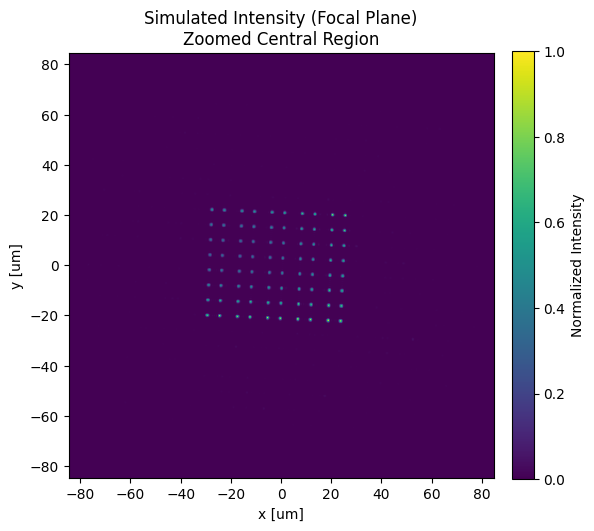

In [110]:
PM.simulate_focal_plane(pm_array3, show=True, zoom_pixels=100, cmap='viridis')

In [111]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.5,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    d_lift=15.0
)

Occupancy via PSF detector (window 9, threshold 8.6).
Transport node initialised.


In [113]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.7377 ms total
Transport complete: 76 frames, 59.9396 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 20 frames, 17.9322 ms total
Transport complete: 76 frames, 59.3734 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 22 frames, 19.2918 ms total
Transport complete: 76 frames, 59.3169 ms total
Images acquired from rearrange

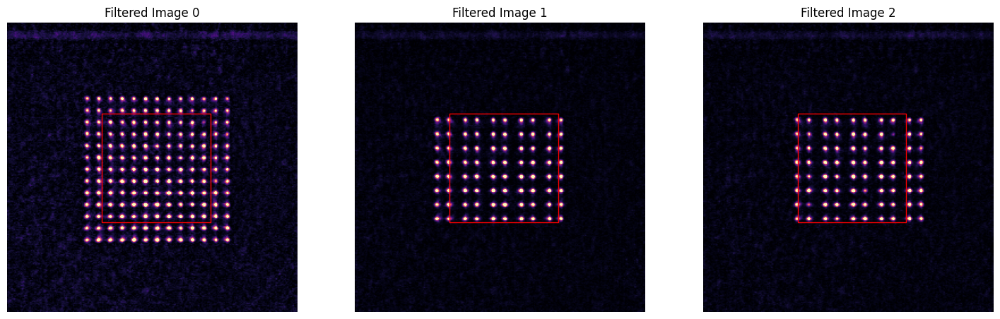

In [116]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 96  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2 - 1, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Trap (0) Loading Probability : 98.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 95.00 %
Trap (3) Loading Probability : 39.00 %
Trap (4) Loading Probability : 95.00 %
Trap (5) Loading Probability : 89.00 %
Trap (6) Loading Probability : 90.00 %
Trap (7) Loading Probability : 85.00 %
Trap (8) Loading Probability : 97.00 %
Trap (9) Loading Probability : 72.00 %
Trap (10) Loading Probability : 76.00 %
Trap (11) Loading Probability : 96.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 93.00 %
Trap (14) Loading Probability : 25.00 %
Trap (15) Loading Probability : 92.00 %
Trap (16) Loading Probability : 80.00 %
Trap (17) Loading Probability : 94.00 %
Trap (18) Loading Probability : 94.00 %
Trap (19) Loading Probability : 92.00 %
Trap (20) Loading Probability : 78.00 %
Trap (21) Loading Probability : 88.00 %
Trap (22) Loading Probability : 64.00 %
Trap (23) Loading Probability : 87.00 %
Trap (24) Loading Probability : 88.00 %
Trap (25) 

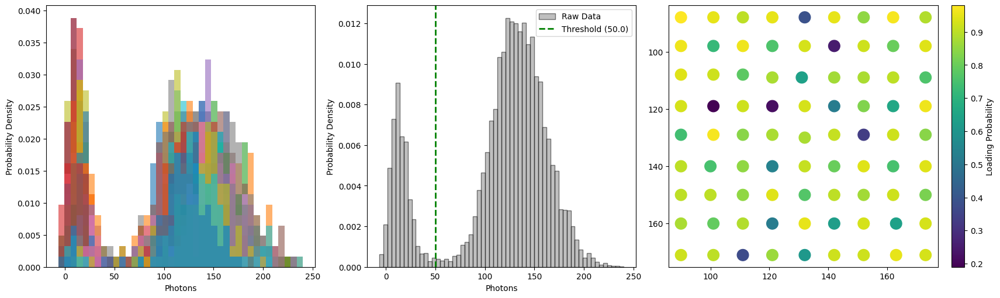

In [ ]:
n = 2
imgs_n_2 = tot_imgs[:, n, :, :]
imgs_n_mean_2 = imgs_n_2.mean(axis=0)
imgs_n_mean_filtered_2 = an.morphological_tophat_high_pass(imgs_n_mean_2, feature_size=feature_size)

imgs_n_filtered_2 = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_n_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_n_filtered_2, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [117]:
hamcam.close()
slm.close()

ImagEM X2 camera closed.
SLM 1 closed.


In [ ]:
  n  